# Notebook 07: Comparative Analysis of the Three Scenarios
**Project:** Real vs. Synthetic Data: Comparative Analysis and Visualization

This notebook compares Scenario 1 (Real, 12,199 sessions), Scenario 2 (Synthetic, 12,199) and Scenario 3 (Combined, 24,398) side by side, with the same settings as notebooks 04 to 06 (shared through `src/scenario_lib.py` and `src/comparison_lib.py`). It produces (1) the comparison table, (2) the comparison charts, (3) the summary matrix and (4) the written answers to the seven questions of the brief.

**Where each chart is built.** Histograms, bars, box-style charts, scatter and line charts are Power BI visuals; they are built natively on the Power BI *Comparison* page in a later phase, from the tables exported at the end of this notebook. The Python versions below give the statistical content and the reference for checking the dashboard. The side-by-side correlation matrices cannot be drawn natively in Power BI and are produced here (they are inserted into the dashboard as images).

## 1. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import scenario_lib as L
import comparison_lib as C
L.use_style()

real = pd.read_csv(ROOT / "data" / "cleaned" / "online_shoppers_cleaned.csv")
syn = pd.read_csv(ROOT / "data" / "synthetic" / "synthetic_online_shoppers.csv")
comb_file = pd.read_csv(ROOT / "data" / "combined" / "combined_dataset.csv")
dfs = C.make_scenarios(real, syn)                       # Real, Synthetic, Combined (without the Data_Source column)
pd.testing.assert_frame_equal(dfs["Combined"], comb_file.drop(columns="Data_Source"), check_exact=False, rtol=1e-9)   # same rows as the saved combined file
S = L.make_settings(real, syn)                          # identical settings for every scenario
FIG = ROOT / "figures" / "comparison"; RES = ROOT / "results" / "comparison"; PBI = RES / "powerbi_tables"
for p in (FIG, RES, PBI): p.mkdir(parents=True, exist_ok=True)
print({k: v.shape for k, v in dfs.items()})

{'Real': (12199, 24), 'Synthetic': (12199, 24), 'Combined': (24398, 24)}


## 2. Comparison table: mean, median, standard deviation, minimum and maximum
One row per numerical column and scenario. Values are not rounded in the CSV (`results/comparison/comparison_table.csv`).

In [2]:
tab = C.stats_table(dfs); tab.to_csv(RES / "comparison_table.csv", index=False)
wide = tab.pivot(index="column", columns="scenario", values=["mean", "median", "std", "min", "max"])
wide = wide.reindex(columns=pd.MultiIndex.from_product([["mean", "median", "std", "min", "max"], C.SC])).loc[L.NUM]
wide.round(3)

mean                       median            \
                             Real Synthetic  Combined     Real Synthetic   
column                                                                     
Administrative              2.340     2.156     2.248    1.000     2.000   
Administrative_Duration    79.493    61.279    70.386    9.000    18.671   
Informational               0.509     0.643     0.576    0.000     0.000   
Informational_Duration     32.767    22.264    27.516    0.000     0.000   
ProductRelated             31.572    32.934    32.253   18.000    17.000   
ProductRelated_Duration  1183.082  1260.716  1221.899  609.542   534.021   
BounceRates                 0.020     0.014     0.017    0.003     0.004   
ExitRates                   0.041     0.040     0.041    0.025     0.025   
PageValues                  5.953     5.746     5.849    0.000     0.000   
SpecialDay                  0.062     0.060     0.061    0.000     0.000   
Total_Pages                34.421    35.733    35.077   20.000    19.000   
Total_Duration           1295.342  1344.259  1319.800  691.357   623.028   
Avg_Time_Per_Page          38.069    43.926    40.997   30.000    31.586   
Product_Page_Share          0.905     0.879     0.892    0.962     0.934   

                                       std                      min            \
                        Combined      Real Synthetic  Combined Real Synthetic   
column                                                                          
Administrative             1.000     3.331     2.601     2.990  0.0       0.0   
Administrative_Duration   13.000   157.518   107.446   135.132  0.0       0.0   
Informational              0.000     1.276     1.007     1.151  0.0       0.0   
Informational_Duration     0.000   120.155    47.692    91.559  0.0       0.0   
ProductRelated            17.000    40.690    46.027    43.445  0.0       1.0   
ProductRelated_Duration  574.695  1652.525  1983.100  1825.687  0.0       0.0   
BounceRates                0.004     0.045     0.025     0.037  0.0       0.0   
ExitRates                  0.025     0.046     0.041     0.044  0.0       0.0   
PageValues                 0.000    18.658    10.209    15.039  0.0       0.0   
SpecialDay                 0.000     0.200     0.196     0.198  0.0       0.0   
Total_Pages               20.000    42.761    47.045    44.958  1.0       1.0   
Total_Duration           656.665  1749.550  2015.256  1887.205  0.0       0.0   
Avg_Time_Per_Page         30.613    42.785    43.337    43.160  0.0       0.0   
Product_Page_Share         0.948     0.141     0.152     0.147  0.0       0.1   

                                        max                        
                        Combined       Real  Synthetic   Combined  
column                                                             
Administrative               0.0     27.000     27.000     27.000  
Administrative_Duration      0.0   1178.967   1178.967   1178.967  
Informational                0.0     24.000      6.000     24.000  
Informational_Duration       0.0   1005.421    501.570   1005.421  
ProductRelated               0.0    282.000    282.000    282.000  
ProductRelated_Duration      0.0  11246.177  11246.177  11246.177  
BounceRates                  0.0      0.200      0.200      0.200  
ExitRates                    0.0      0.200      0.200      0.200  
PageValues                   0.0    361.764    125.004    361.764  
SpecialDay                   0.0      1.000      1.000      1.000  
Total_Pages                  1.0    323.000    297.000    323.000  
Total_Duration               0.0  13430.566  12581.501  13430.566  
Avg_Time_Per_Page            0.0   1364.000    605.713   1364.000  
Product_Page_Share           0.0      1.000      1.000      1.000

**Interpretation.** The three scenarios agree closely on the centre of most columns and differ in the spread of the sparse ones. Means differ by less than 8% in nine of 14 columns (this count depends on the threshold: 7, 9, 9 and 9 columns are within 5%, 8%, 10% and 15%; ExitRates 0.041 against 0.040, PageValues 5.95 against 5.75, Total_Pages 34.4 against 35.7); the largest gaps are Informational_Duration (32.8 s real, 22.3 s synthetic, -32%), BounceRates (-32%), Administrative_Duration (-23%) and Informational (+26%). The combined mean always lies between the two (Informational_Duration 27.5 s). Medians are equal or within 10% in ten columns; the four exceptions are Administrative (1 real, 2 synthetic), Administrative_Duration (9 s, 18.7 s), ProductRelated_Duration (610 s, 534 s, -12%) and BounceRates (0.0029, 0.0043). Standard deviations separate more: Informational_Duration 120 against 48, PageValues 18.7 against 10.2 and BounceRates 0.045 against 0.025 are much smaller in the synthetic data, while ProductRelated_Duration (1,653 against 1,983) and Total_Duration (1,750 against 2,015) are larger. Minima are 0 in every column except Total_Pages (1 in all three scenarios), the synthetic ProductRelated (1) and the synthetic Product_Page_Share (0.1). The real maximum is exceeded by no scenario; the synthetic maximum is lower for six columns (for example PageValues 125 against 362, Informational 6 against 24) and the combined maximum equals the real one in all 14 columns.

In [3]:
dist = C.distance_to_real(dfs); dist.to_csv(RES / "distance_to_real.csv", index=False)
dist.pivot(index="column", columns="scenario", values=["KS", "mean diff (%)", "Cohen d", "std ratio"]).loc[L.NUM].round(3)

KS           mean diff (%)            Cohen d  \
scenario                Combined Synthetic      Combined Synthetic Combined   
column                                                                        
Administrative             0.045     0.090        -3.932    -7.864   -0.029   
Administrative_Duration    0.023     0.046       -11.456   -22.913   -0.062   
Informational              0.063     0.127        13.207    26.413    0.055   
Informational_Duration     0.047     0.094       -16.026   -32.053   -0.049   
ProductRelated             0.015     0.031         2.157     4.313    0.016   
ProductRelated_Duration    0.022     0.045         3.281     6.562    0.022   
BounceRates                0.024     0.047       -15.889   -31.778   -0.078   
ExitRates                  0.016     0.031        -1.734    -3.467   -0.016   
PageValues                 0.068     0.136        -1.732    -3.464   -0.006   
SpecialDay                 0.002     0.004        -1.839    -3.677   -0.006   
Total_Pages                0.017     0.033         1.906     3.812    0.015   
Total_Duration             0.026     0.052         1.888     3.776    0.013   
Avg_Time_Per_Page          0.038     0.076         7.692    15.384    0.068   
Product_Page_Share         0.043     0.087        -1.405    -2.810   -0.088   

                                  std ratio            
scenario                Synthetic  Combined Synthetic  
column                                                 
Administrative             -0.062     0.898     0.781  
Administrative_Duration    -0.135     0.858     0.682  
Informational               0.117     0.902     0.789  
Informational_Duration     -0.115     0.762     0.397  
ProductRelated              0.031     1.068     1.131  
ProductRelated_Duration     0.043     1.105     1.200  
BounceRates                -0.177     0.811     0.553  
ExitRates                  -0.033     0.952     0.901  
PageValues                 -0.014     0.806     0.547  
SpecialDay                 -0.012     0.991     0.982  
Total_Pages                 0.029     1.051     1.100  
Total_Duration              0.026     1.079     1.152  
Avg_Time_Per_Page           0.136     1.009     1.013  
Product_Page_Share         -0.173     1.044     1.079

**Interpretation.** The table gives the distance of the Synthetic and of the Combined data from the Real data for each column. The Combined distances are about half of the Synthetic ones in every column (for example KS 0.068 against 0.136 for PageValues, mean difference -16.0% against -32.1% for Informational_Duration), because half of the combined rows are the real rows. The standardised mean difference (Cohen's d) never reaches 0.2 (largest -0.177 for BounceRates in the Synthetic data, -0.088 in the Combined data); KS is above 0.05 in seven columns of the Synthetic data and in two (PageValues, Informational) of the Combined data.

## 3. Comparison charts
### 3.1 Three-way distribution plot

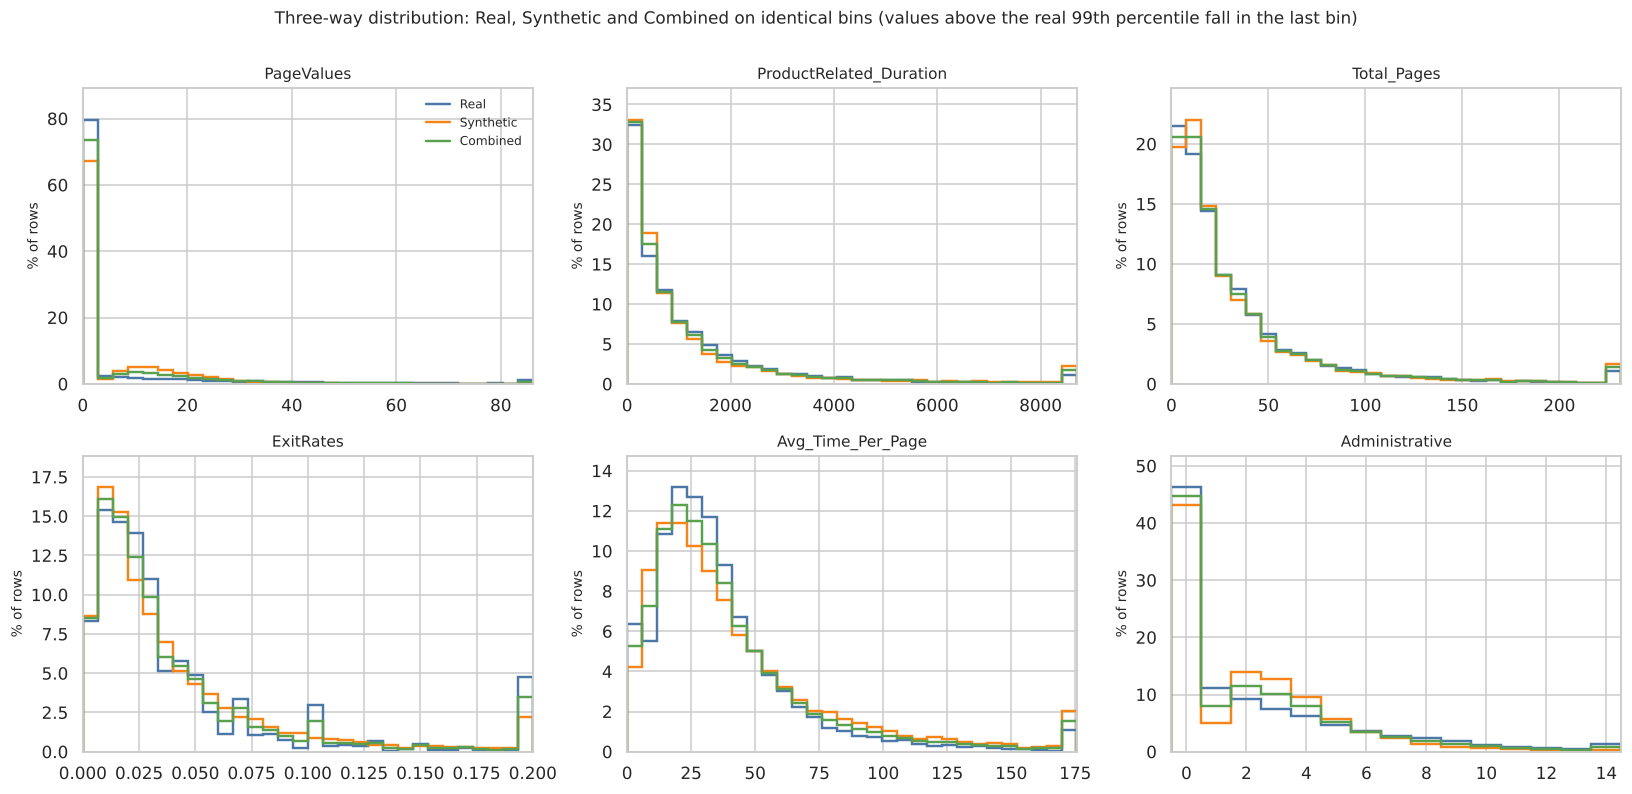

In [4]:
C.fig_three_way_distribution(dfs, S, FIG / "c01_three_way_distribution.png")

**Interpretation.** The three step histograms use identical bins and axes. For ProductRelated_Duration, Total_Pages and ExitRates the three lines almost coincide. The visible differences are in the sparse columns: the first bin of PageValues is lower for the Synthetic data (zeros: 77.6% real, 67.1% synthetic, 72.4% combined) with a small synthetic excess at 5 to 20; the synthetic Administrative counts have more mass at 2 to 4 pages and fewer at 1; the synthetic Avg_Time_Per_Page is flatter and shifted to the right (mean 43.9 s against 38.1 s); and the spike at the cap of 0.2 in ExitRates is smaller in the Synthetic data (2.0% of rows against 4.8%). The Combined line (green) always lies between the other two.

### 3.2 Mean, median and standard deviation

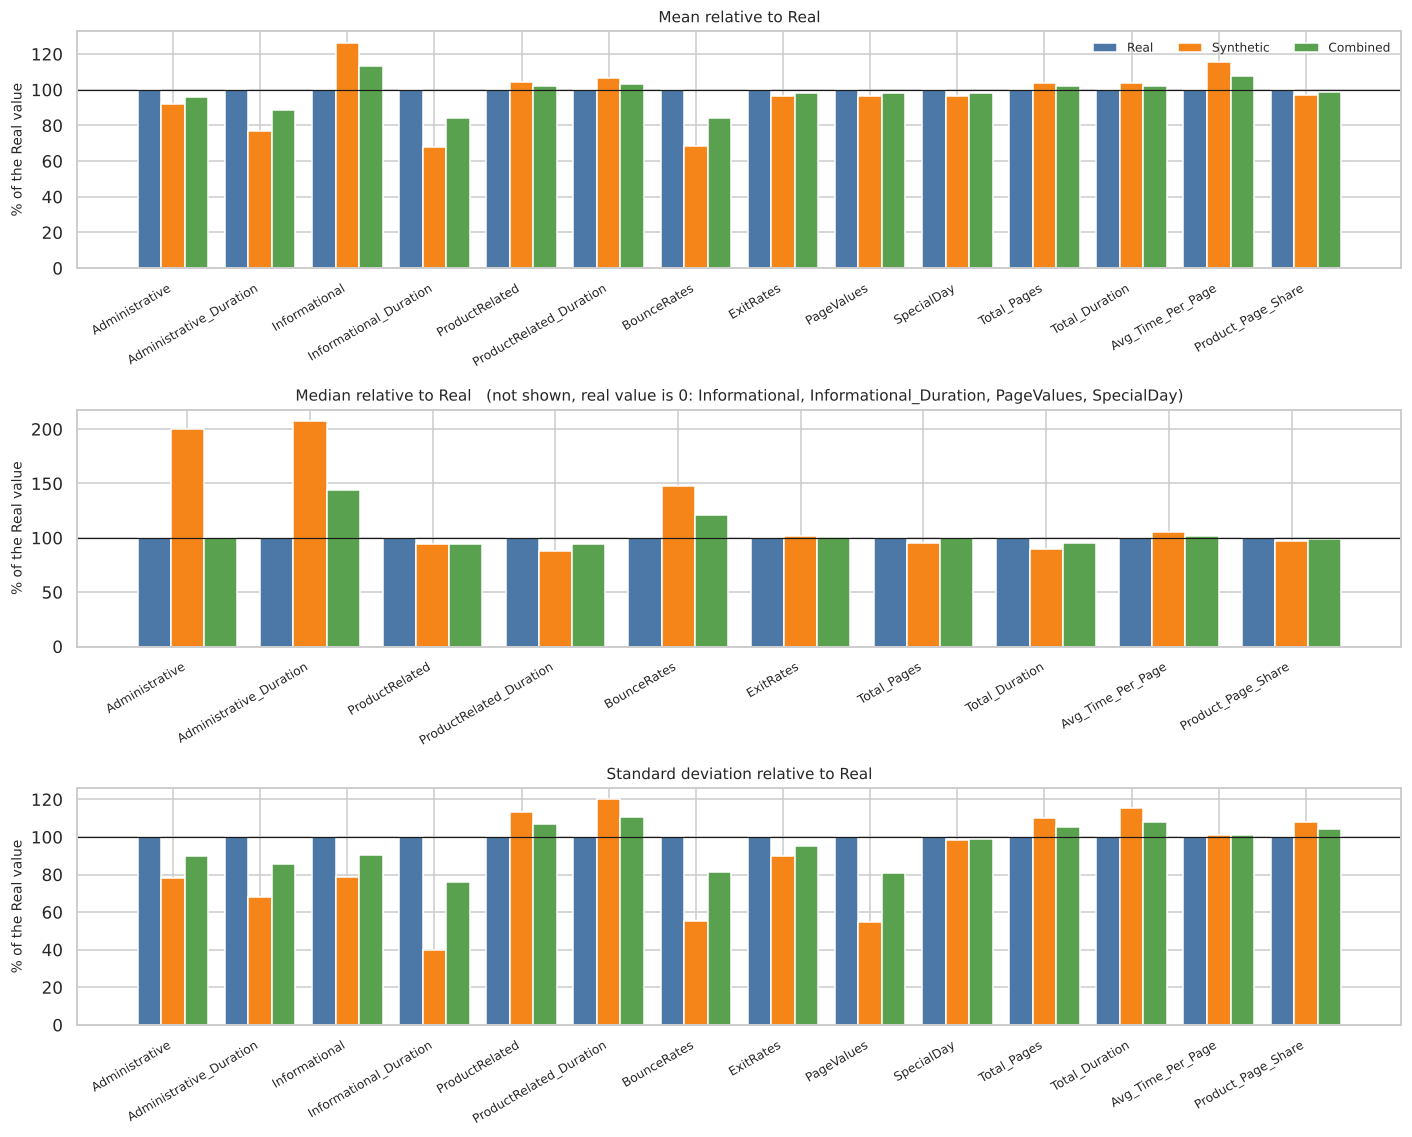

In [5]:
C.fig_mean_median_std(tab, FIG / "c02_mean_median_std.png")

**Interpretation.** Each bar is a statistic as a percentage of the real value (the line at 100). Means (top): Synthetic ranges from 68% (Informational_Duration, BounceRates) to 126% (Informational), and the Combined bars are always closer to 100. Medians (middle): equal for most columns, with Administrative (2 against 1) and Administrative_Duration (18.7 against 9) at about 200%, BounceRates at 148% and ProductRelated_Duration at 88%; these are large percentages of small numbers. Four columns have a real median of 0 (Informational, Informational_Duration, PageValues, SpecialDay) and are listed in the title; the synthetic median is 0 too for these columns. Standard deviations (bottom) show the clearest pattern: the Synthetic data is less spread out in the sparse columns (Informational_Duration 40%, PageValues 55%, BounceRates 55%) and more spread out in the browsing columns (ProductRelated_Duration 120%, Total_Duration 115%, Total_Pages 110%). Combined values are 76% to 110% of the real standard deviation.

### 3.3 Comparative box plots

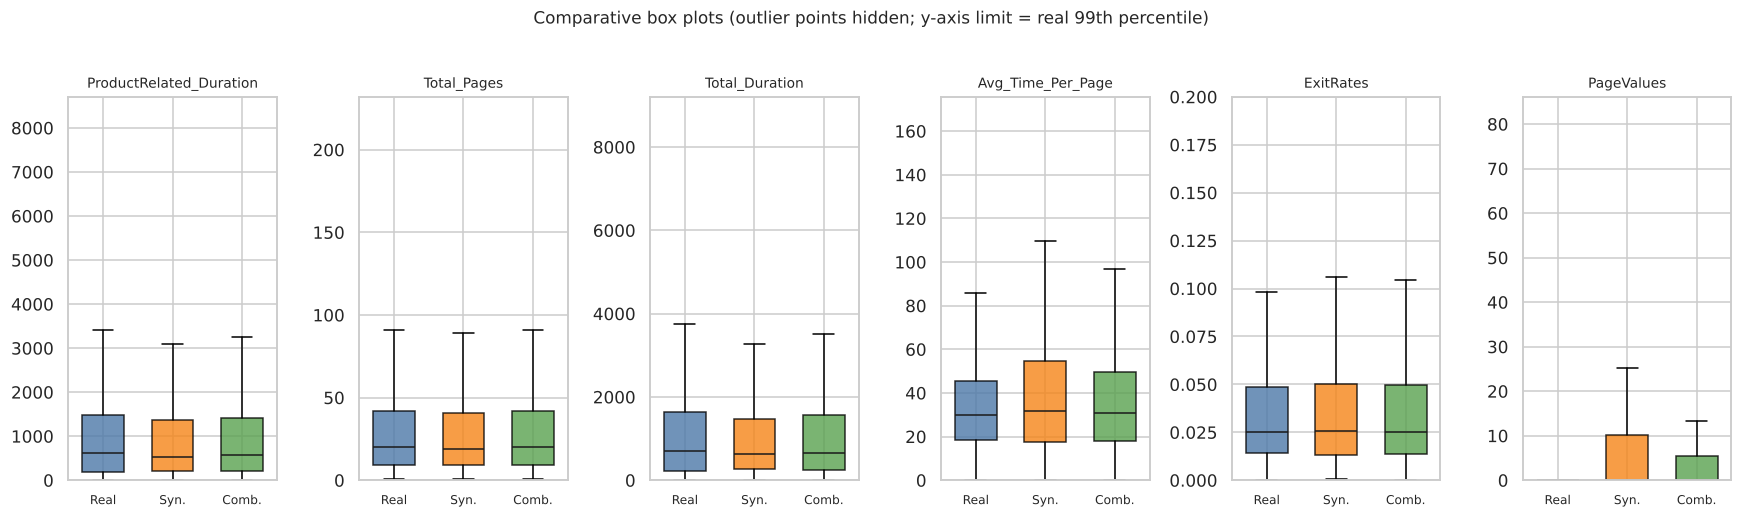

In [6]:
C.fig_boxes(dfs, S, FIG / "c03_comparative_boxplots.png")

**Interpretation.** The comparative box plots (outliers hidden) agree for the browsing columns ProductRelated_Duration, Total_Pages, Total_Duration and ExitRates: medians and quartiles of the three scenarios are almost equal. The Synthetic box of Avg_Time_Per_Page is taller (third quartile and whisker higher), and in PageValues the real box collapses at 0, while the synthetic box reaches about 10 and the combined box about 5. This is the same difference as in the histograms: the synthetic data has more non-zero PageValues in the middle range and fewer extreme values.

### 3.4 Side-by-side correlation matrices (Python; inserted into the dashboard as images)

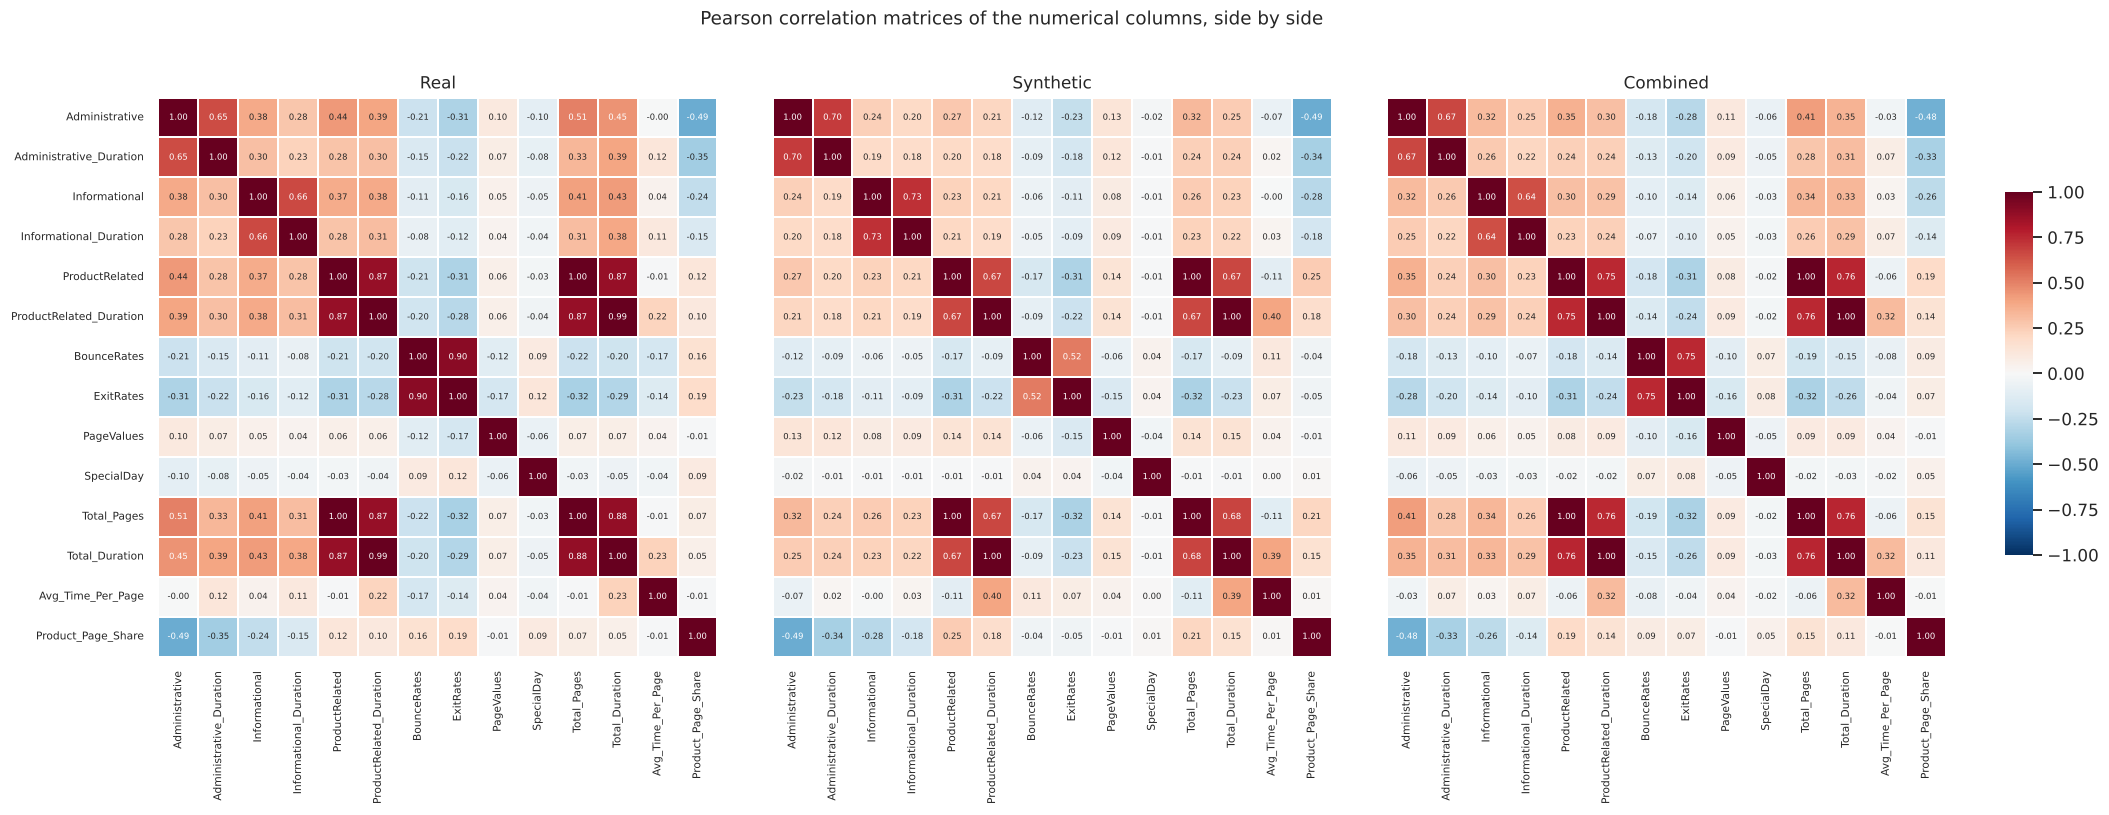

In [7]:
C.fig_corr_side_by_side(dfs, "pearson", FIG / "c04_correlation_pearson_side_by_side.png")

**Interpretation.** The three Pearson matrices have the same block structure: the counts and their durations are positively correlated, Product_Page_Share is negatively correlated with the Administrative columns (-0.49 in the Real and the Synthetic data, -0.48 in the Combined data), and PageValues is only weakly correlated with the other columns (at most -0.17 with ExitRates in the Real data). The strongest correlations are weakened in the Synthetic matrix: BounceRates with ExitRates falls from 0.90 to 0.52 and ProductRelated with ProductRelated_Duration from 0.87 to 0.67 (Combined: 0.75 and 0.75). The synthetic matrix also has relationships that are stronger than in the real data: ProductRelated_Duration with Avg_Time_Per_Page is 0.40 against 0.22. The Combined matrix is closer to Real than the Synthetic matrix (mean absolute difference 0.043 against 0.091). For 84 of the 91 pairs the Combined correlation lies between the Real and the Synthetic value, but this is not guaranteed, because pooling two samples does not average their correlations.

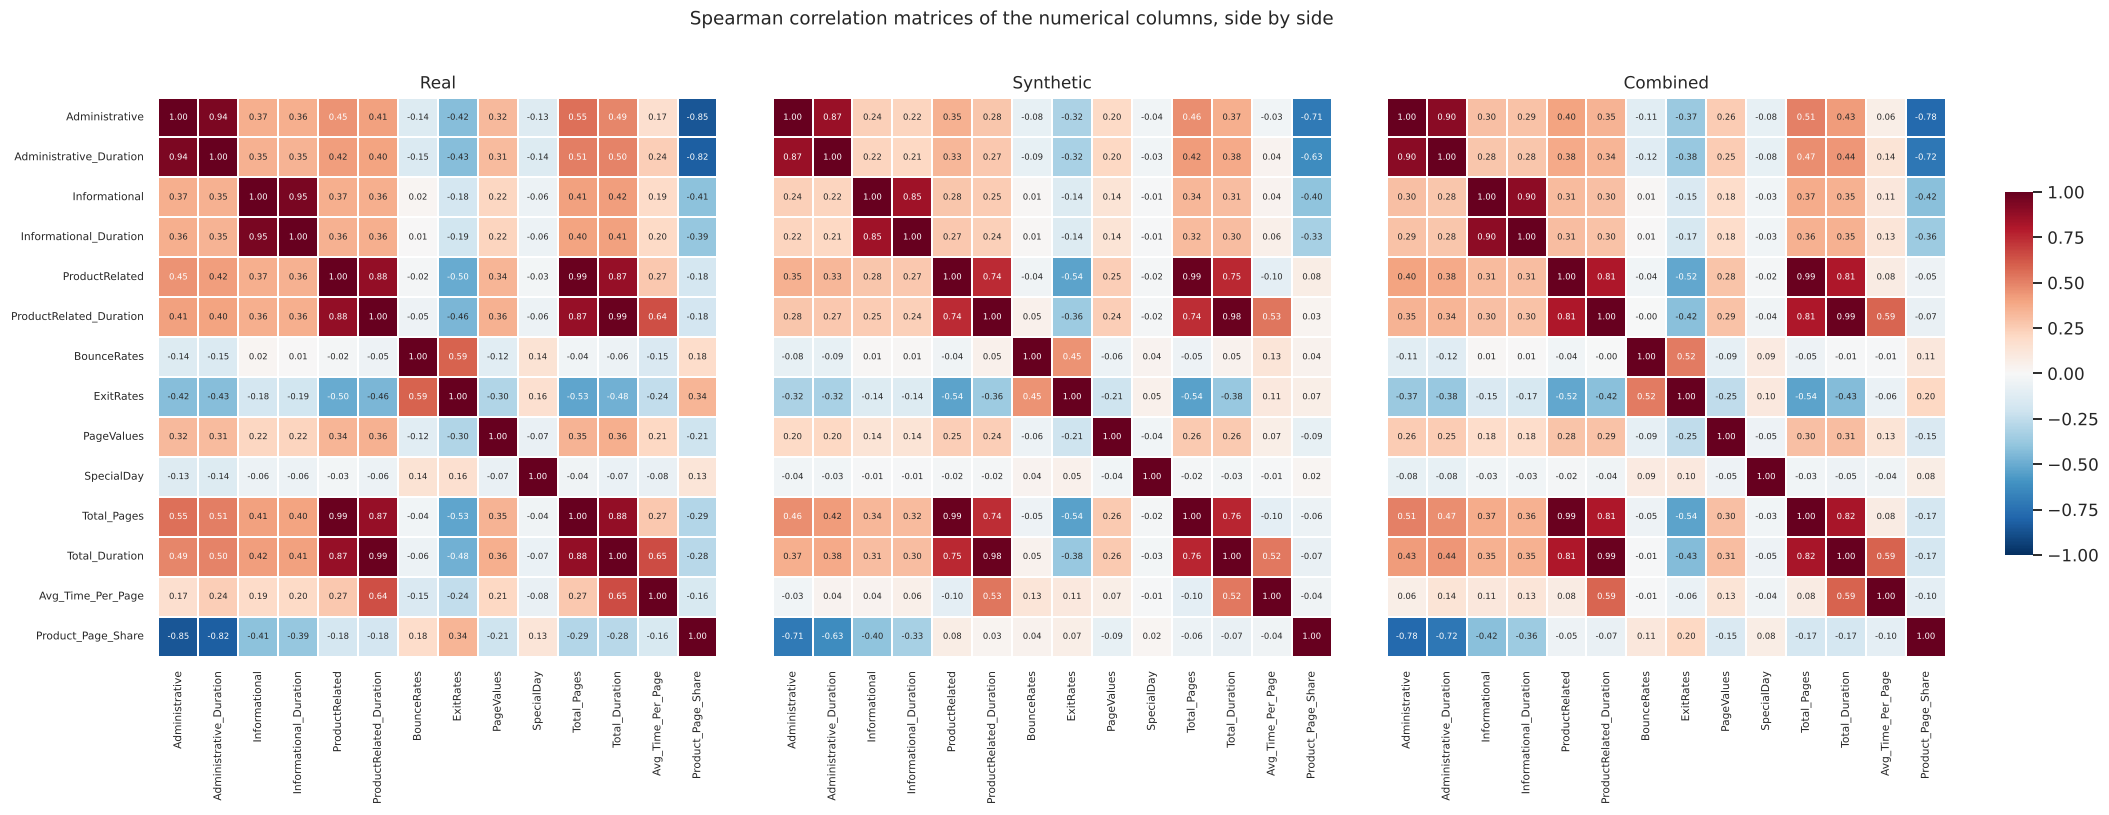

In [8]:
C.fig_corr_side_by_side(dfs, "spearman", FIG / "c05_correlation_spearman_side_by_side.png")

**Interpretation.** The rank correlations tell the same story. Pairs between a count and its duration remain high (Administrative with its duration 0.94 real, 0.87 synthetic, 0.90 combined; Informational 0.95, 0.85, 0.90) and the negative block of Product_Page_Share remains (Administrative -0.85, -0.71, -0.78). The differences are largest for Avg_Time_Per_Page, which is a derived column: its Spearman correlation with Total_Pages is +0.27 in the Real data and -0.10 in the Synthetic data, with ProductRelated and with ExitRates the differences are 0.37 and 0.35. In total, 7 of the 77 pairs with a real correlation of at least 0.1 in magnitude change sign in the Synthetic data and none in the Combined data; among the 49 pairs with a real correlation of at least 0.3 none changes sign (Pearson: 4 of 61 pairs with |r| ≥ 0.1 and 0 of 30 pairs with |r| ≥ 0.3).

### 3.5 Categorical distribution comparison

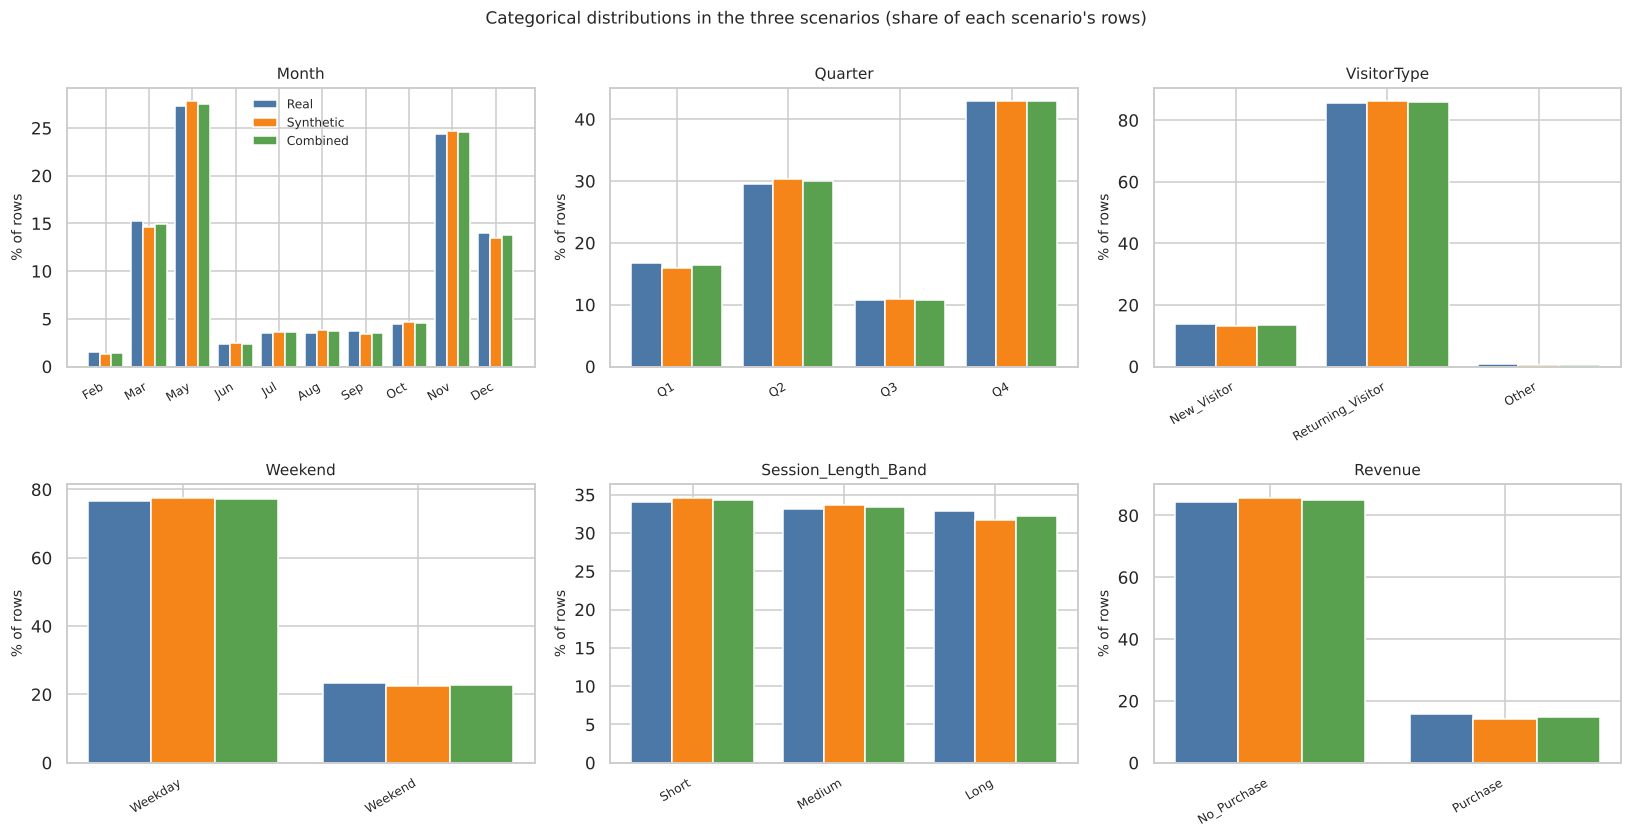

In [9]:
C.fig_categorical(dfs, S, FIG / "c06_categorical_comparison.png")

**Interpretation.** The grouped bars of the three scenarios are almost identical for all six categorical columns shown. The monthly traffic has the same peaks in May (27.3% real, 27.8% synthetic) and November (24.4% and 24.7%), 77% of the sessions are on weekdays, the three session-length bands are about equally frequent, and the purchase share is 15.6% (Real), 14.2% (Synthetic) and 14.9% (Combined). The largest gap in any category share between the Real and the Synthetic data is 1.45 percentage points (Revenue), and the Combined shares are at most 0.73 percentage points from the real shares. In chi-square tests only Revenue (p = 0.0015) and, borderline, Weekend (p = 0.046) differ between Real and Synthetic.

### 3.6 One relationship across all three scenarios, with fitted lines

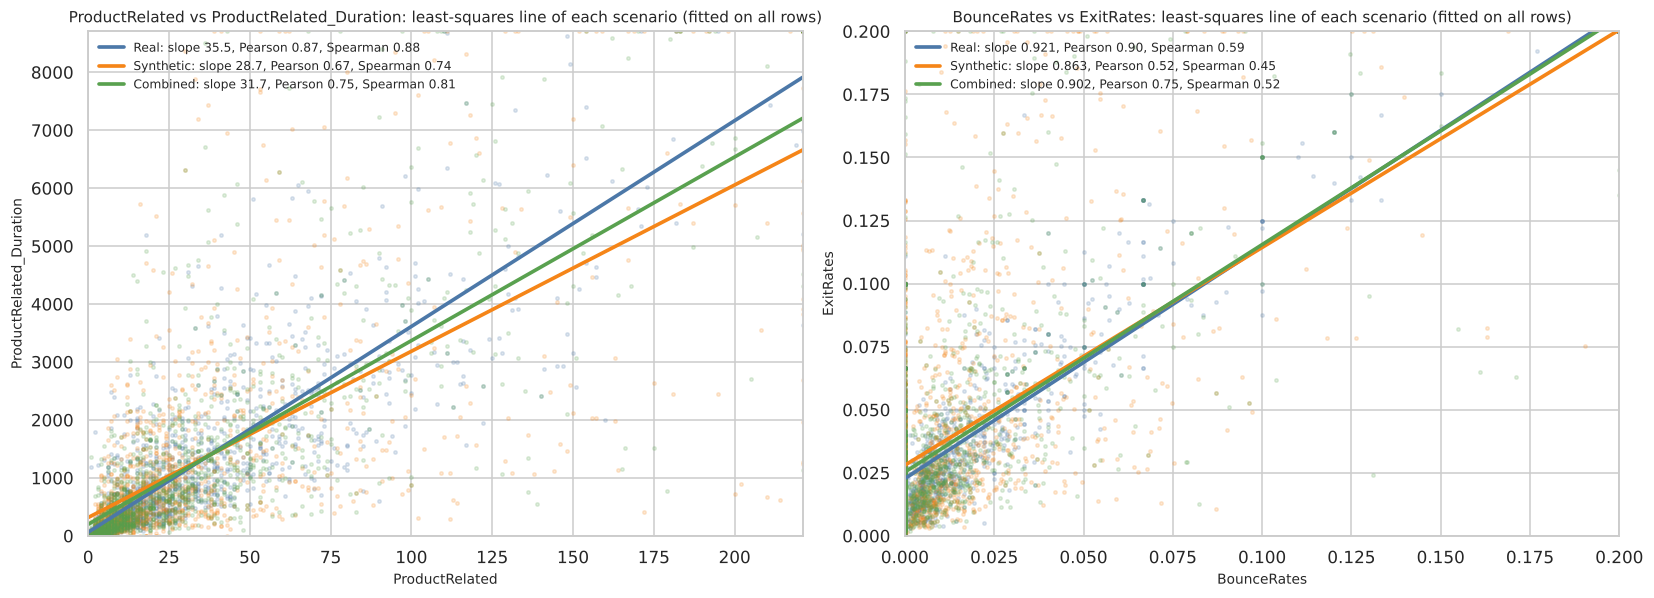

In [10]:
C.fig_relationship(dfs, S, FIG / "c07_relationship_fitted_lines.png")

**Interpretation.** Each line is a least-squares line fitted on all rows of one scenario (the points are a random sample of 1,500 rows per scenario). ProductRelated and its duration: the slope is 35.5 seconds per page in the Real data, 28.7 in the Synthetic data and 31.7 in the Combined data, and the correlation falls from 0.87 (Pearson) to 0.67 and 0.75. BounceRates and ExitRates: the three lines nearly coincide (slope 0.92, 0.86, 0.90), but the correlation drops from 0.90 to 0.52 and 0.75, because the synthetic points scatter much more around the line. A similar fitted line therefore does not mean a similar relationship: the strength of the relationship has to be checked next to the line.

### 3.7 Monthly trend across the three scenarios

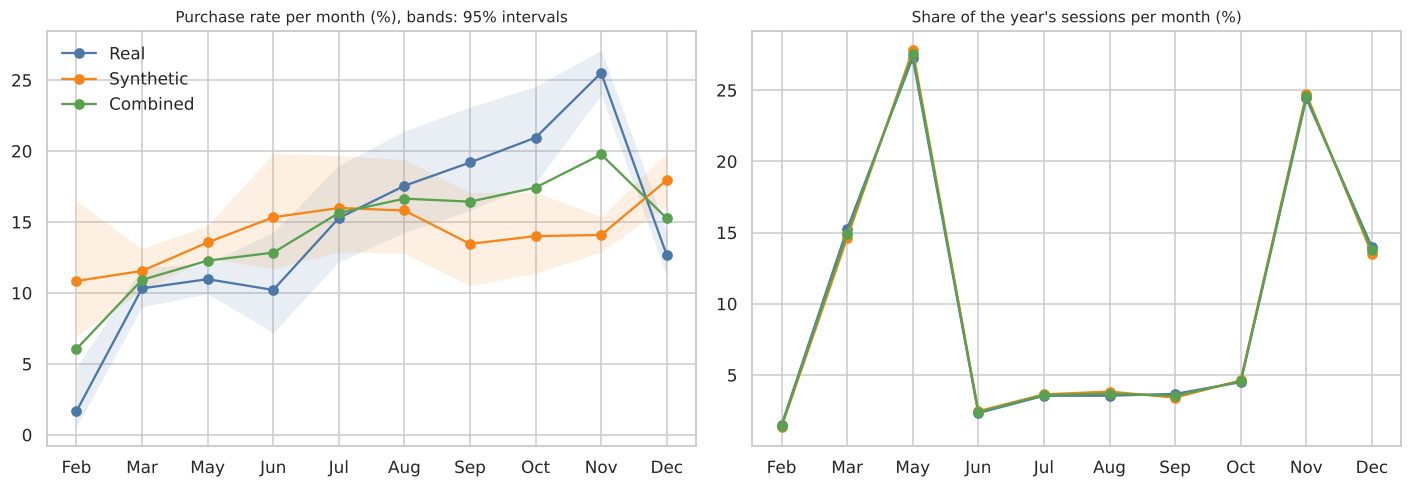

In [11]:
C.fig_trend(dfs, FIG / "c08_monthly_trend.png")

**Interpretation.** The share of sessions per month (right) is reproduced by the Synthetic data to within 0.63 percentage points (peaks in May and November), so the traffic pattern is kept. The purchase rate per month (left) is not: the Real data rises from 1.7% in February to 25.5% in November, the Synthetic data stays between 10.8% and 18.0%, peaks in December and has a rank correlation with the real monthly rates of only 0.28. The Combined line follows the real shape (rank correlation 0.95) with a range of 6.1% to 19.8%, so the seasonality is kept in direction and understated in size; the high rank correlation is largely mechanical, because half of the Combined rows are the real rows. The monthly rates rest on very different numbers of sessions: the real February has only 181 sessions (3 purchases, 95% interval 0.6% to 4.8%) and June 284, against more than 2,900 in May and November, as the shaded bands show. The synthetic rate lies outside the real 95% interval in seven of the ten months (February, May, June, September, October, November, December), so the lost seasonality is not an artefact of the small months.

## 4. Evidence for the summary matrix and the written answers
Every number quoted in the summary matrix and in the answers below is computed here. Cramér's V uses the chi-square statistic without continuity correction. The drivers table gives the effect of each attribute on purchase (rank-biserial correlation for numerical, Cramér's V for categorical columns) in the three scenarios.

In [12]:
E = C.summary_evidence(dfs)
drivers = E.pop("driver_table"); drivers.round(3).to_csv(RES / "purchase_drivers.csv")
cm = C.categorical_match(dfs); cm.round(4).to_csv(RES / "categorical_match.csv")
json.dump({k: (round(v, 6) if isinstance(v, float) else v) for k, v in E.items()}, open(RES / "evidence.json", "w"), indent=1)
display(drivers.round(3)); display(cm.round(4))
print("Sensitivity of the counts to the thresholds -> means within 5/8/10/15%:", E["thr_mean"], "| combined:", E["thr_mean_comb"])
print("KS above 0.03/0.05/0.10:", E["thr_ks"], "| combined:", E["thr_ks_comb"])
print("Combined correlation between Real and Synthetic:", E["comb_corr_pearson_between"], "of", E["corr_pearson_pairs"], "Pearson pairs;", E["comb_corr_spearman_between"], "of", E["corr_spearman_pairs"], "Spearman pairs")

,Real,Synthetic,Combined
PageValues (rank-biserial),0.726,0.302,0.526
ExitRates (rank-biserial),0.399,0.175,0.289
Total_Pages (rank-biserial),0.318,0.141,0.234
Total_Duration (rank-biserial),0.344,0.151,0.256
BounceRates (rank-biserial),0.217,0.065,0.148
Avg_Time_Per_Page (rank-biserial),0.228,0.050,0.135
Session_Length_Band (Cramer's V),0.185,0.078,0.132
Month (Cramer's V),0.176,0.053,0.096
Quarter (Cramer's V),0.137,0.039,0.087
VisitorType (Cramer's V),0.103,0.036,0.070


,levels,chi2,p-value,Cramer's V,largest share gap (pp)
column,,,,,
Month,10,7.4636,0.5890,0.0175,0.6312
Quarter,4,3.1064,0.3755,0.0113,0.7542
VisitorType,3,2.5199,0.2837,0.0102,0.7050
Weekend,2,3.9849,0.0459,0.0128,1.0739
OperatingSystems,8,7.7570,0.3545,0.0178,1.4263
Browser,13,4.6378,0.9690,0.0138,0.5246
Region,9,11.1002,0.1961,0.0213,0.4918
TrafficType,20,13.5131,0.8113,0.0235,0.8935
Session_Length_Band,3,3.6323,0.1627,0.0122,1.1394


Sensitivity of the counts to the thresholds -> means within 5/8/10/15%: {5: 7, 8: 9, 10: 9, 15: 9} | combined: {5: 9, 8: 10, 10: 10, 15: 12}
KS above 0.03/0.05/0.10: {0.03: 13, 0.05: 7, 0.1: 2} | combined: {0.03: 6, 0.05: 2, 0.1: 0}
Combined correlation between Real and Synthetic: 84 of 91 Pearson pairs; 89 of 91 Spearman pairs


**Interpretation.** Effect sizes of purchase drivers (rank-biserial for numerical, Cramér's V for categorical columns): the Synthetic values are between 14% and 44% of the Real values (Weekend 14% is the lowest and Total_Pages 44% the highest; PageValues 0.73 real and 0.30 synthetic, 42%; session length 0.185 and 0.078, 42%; month 0.176 and 0.053, 30%), and the Combined values are in between. The ranking of the 11 drivers is almost the same in the three scenarios (Spearman correlation 0.94 between Real and Synthetic, 0.99 between Real and Combined) and PageValues is the strongest driver in all three; so the synthetic data keeps the order of the drivers but not their strength. The 11 values mix two scales (rank-biserial correlation for numerical and Cramér's V for categorical columns), so the overall ranking is a rough guide; within the six numerical drivers the Spearman correlation with Real is 0.94 for both Synthetic and Combined, and the five categorical drivers have the same order in all three scenarios. For the categorical columns, Cramér's V between data source and column is between 0.010 and 0.024; VisitorType (0.010), Quarter (0.011) and Session_Length_Band (0.012) match best, TrafficType (0.024), Region (0.021) and Revenue (0.020) least well, although all are very small. Chi-square tests of data source against each categorical column (without continuity correction) show no significant difference in eight of ten columns (p from 0.16 to 0.97); Revenue (chi-square 10.1, p = 0.0015; 14.2% against 15.6% purchases) and Weekend (chi-square 4.0, p = 0.046) differ, although the effects are tiny (Cramér's V 0.020 and 0.013), and with a Bonferroni correction for ten tests (threshold 0.005) only Revenue remains significant. With 12,199 rows per source even a difference of 1.4 percentage points is detectable. The largest gap in any category share is smallest for Region (0.49 pp) and largest for Revenue (1.45 pp).

## 5. Summary matrix

In [13]:
sm = C.summary_matrix(E); sm.to_csv(RES / "summary_matrix.csv")
sm

,Real vs. Synthetic,Effect of the Combined dataset
Aspect,,
Mean,Within 8% of the real mean for 9 of 14 columns...,Combined mean is the average of the two source...
Median,Within 10% of the real median (or both 0) for ...,Within 10% of the real median (or both 0) for ...
Variance (standard deviation),Std ratio Synthetic/Real from 0.40 (Informatio...,Std ratio Combined/Real from 0.76 (Information...
Distribution shape,KS above 0.05 in 7 of 14 columns (above 0.03 /...,KS to Real above 0.05 in 2 of 14 columns (abov...
Categorical proportions,Cramér's V between source and column 0.010 to ...,Largest share gap of Combined to Real 0.73 pp:...
Correlation,Mean |Δ Pearson| over 91 pairs 0.091 (max 0.38...,Mean |Δ Pearson| to Real 0.043 (max 0.15); 0 s...
Outliers and extremes,"PageValues outliers 22.4% real, 5.8% synthetic...",Combined maximum equals the real maximum in 14...
Trends (monthly),Monthly purchase rate 1.7% to 25.5% real (Nov ...,Combined range 6.1% to 19.8%; the seasonal pat...
Analytical patterns (drivers of purchase),"Purchase rate 15.64% real, 14.19% synthetic; t...",Combined purchase rate 14.92%; driver ranking ...


**Interpretation.** The summary matrix collects the evidence of this notebook. In short: the Synthetic data is close to the Real data in means, medians and category shares, less close in variance and distribution shape, and clearly different in correlation strength, monthly conversion and the size of the purchase effects. The Combined dataset does not add any information: for most rows its value lies between the Real and the Synthetic value (for the means by construction, for 84 of 91 Pearson correlations by observation), usually close to the middle, so it reduces the visible differences without being closer to the truth. Counts such as "9 of 14 means within 8%" depend on the threshold (7, 9, 9 and 9 columns within 5%, 8%, 10% and 15%; KS above 0.03, 0.05 and 0.10 in 13, 7 and 2 columns), so they are read as a pattern and not as pass or fail results.

## 6. Written answers to the questions of the brief

### Question 1: How similar are the real and the synthetic data?
**Similar in the centre and in category proportions, less similar in shape, spread and relationships.** Nine of 14 numerical means are within 8% of the real means (seven within 5%), no standardised mean difference reaches 0.2 (largest -0.177), and the category shares of all ten categorical columns match very well (Cramér's V between data source and column 0.010 to 0.024; largest share gap 1.45 percentage points; only Revenue, p = 0.0015, and Weekend, p = 0.046, differ significantly in a chi-square test, with tiny effects). The distributions differ more than the means: seven columns have a KS statistic above 0.05 (mean KS 0.064, which is about the same as the 0.059 obtained by sampling every column independently), standard deviations are 40% to 120% of the real ones, and the strongest correlations are weakened (mean absolute difference 0.091 over 91 Pearson pairs, against 0.22 for independent sampling). The synthetic data is not a copy: no synthetic row is identical to a real row, whereas a bootstrap sample would have been 100% identical.

### Question 2: Which numerical column differs most, and which categorical column matches best?
**Numerical:** the answer depends on the measure. By distribution shape it is PageValues (KS 0.136), by mean and by spread it is Informational_Duration (mean -32.1%, standard deviation 40% of the real one; BounceRates has the same mean difference, -31.8%, and the largest standardised difference, d = -0.177). The sparse, zero-heavy columns differ most; the columns of the browsing group (ProductRelated, Total_Pages, Total_Duration, ExitRates, SpecialDay) differ least (KS 0.004 to 0.052).
**Categorical:** VisitorType matches best by Cramér's V (0.010; Quarter 0.011 and Session_Length_Band 0.012 follow); by the largest gap in any level share the best is Region (0.49 pp). The least good match is TrafficType by Cramér's V (0.024) and Revenue by share gap (1.45 pp), but even these are very close; Revenue is also the only column whose difference survives a Bonferroni correction (p = 0.0015; 14.2% against 15.6% purchases). Only one-way proportions match; the associations between categorical columns do not (see Question 6).

### Question 3: Are correlations and trends preserved?
**Correlations: partly.** The block structure and the signs of the strong relationships are kept (4 of 61 Pearson pairs with |r| ≥ 0.1 change sign, 7 of 77 Spearman pairs; none of the 30 Pearson and 49 Spearman pairs with |r| ≥ 0.3), but the strength is not: mean absolute difference 0.091 (Pearson) and 0.111 (Spearman); BounceRates with ExitRates 0.90 to 0.52, ProductRelated with its duration 0.87 to 0.67. Relationships of the derived column Avg_Time_Per_Page change most (Spearman with Total_Pages +0.27 to -0.10).
**Trends: traffic yes, conversion no.** The monthly share of sessions is reproduced to within 0.63 pp, but the monthly purchase rate is not: 1.7% to 25.5% in the real data (peak in November) against 10.8% to 18.0% in the synthetic data (peak in December), rank correlation of the ten months 0.28 (seven of the ten synthetic rates lie outside the real 95% interval; February has only 181 real sessions, so single months are uncertain). **Patterns:** the order of the purchase drivers is kept (Spearman 0.94, PageValues first) but their strength falls to between 14% and 44% of the real size (PageValues 0.73 to 0.30, 42%), and the weekend effect disappears (p = 0.0024 real, 0.69 synthetic).

### Question 4: How does combining affect the mean, the standard deviation and the outliers?
**Mean:** the combined mean is the average of the two sources, so differences from the real mean are halved (largest gap Informational_Duration -16.0% against -32.1%; 10 of 14 columns within 8%). **Standard deviation:** the combined value is 76% to 110% of the real one; it is lowered in the sparse columns (Informational_Duration 0.76, PageValues 0.81, BounceRates 0.81) and raised in the browsing columns (ProductRelated_Duration 1.10, Total_Duration 1.08), because the synthetic data has less spread in the first group and more in the second. **Outliers:** combining creates no new extremes (the combined maximum equals the real maximum in all 14 columns, and the synthetic maximum is lower in six), but the share of rows flagged as outliers becomes a mixture that describes neither source (PageValues 22.4% real, 5.8% synthetic, 15.9% combined). The combined data is therefore closer to the real distributions than the synthetic data alone (mean KS to Real 0.032 against 0.064) but also halves the purchase effects (PageValues effect 0.53 against 0.73).

### Question 5: Which scenario best represents the population?
**The Real dataset (Scenario 1).** It is the only scenario measured from actual sessions; the other two are derived from it. The Combined dataset looks closer to the real data than the Synthetic data in the marginal distributions (mean KS 0.032 against 0.064), but this is only because half of its rows are real rows; for the relationships that matter it is further from the truth than the real data (purchase rate 14.9% against 15.6%, PageValues effect 28% lower, month association 45% lower), and its confidence intervals are too narrow, so that the real purchase rate lies outside the combined 95% interval (14.5% to 15.4%). The Synthetic data represents the population's traffic pattern and category mix well, but not its conversion behaviour. The real data is itself one sample of ten months from one website, so even Scenario 1 represents that website and not all online shoppers.

### Question 6: What are the limitations of the generation method?
The generator is a Gaussian copula with a separate model for the zero values (a hurdle design), fitted once to 12,199 cleaned real rows (seed 42). (1) A Gaussian copula models only linear-type dependence between columns, so the associations between categorical columns are largely lost: the mean absolute difference of Cramér's V over the 45 categorical pairs is 0.10, and OperatingSystems with Browser falls from 0.59 to 0.12 and VisitorType with Browser from 0.50 to 0.04. (2) The purchase signal is weakened: the mean PageValues of purchasing sessions is 27.3 in the real data and 11.0 in the synthetic data, so the effect sizes of the drivers are 14% to 44% of the real ones and the monthly conversion pattern is lost. (3) The numerical marginals are not better than independent sampling (mean KS 0.064 against 0.059), because zero-inflated, capped columns are hard to model; the maxima of six columns are not reached. (4) The synthetic data contains no information that is not in the real sample, so it cannot correct its bias or small groups (for example only 81 sessions of the visitor type Other in the real data). (5) Only one generator was used, by design, to keep the results reproducible on any machine; richer generators such as CTGAN or TVAE might reproduce more associations but were not tested. (6) The privacy check counts exact copies (none), not closeness to individual real rows.

### Question 7: Can the synthetic data replace the real data for analysis?
**Not for analysis whose conclusions depend on effect sizes, seasonality or associations; yes, with care, for tasks that need only the marginal distributions and the overall structure.** The synthetic data reproduces category proportions, traffic seasonality, the centre of the numerical columns and the order of the purchase drivers, and it contains no real row, so it is suitable for developing and testing dashboards and code, for teaching, and for sharing the structure of the data. It is not a substitute for the real data when one must estimate how strongly a factor affects purchase (14% to 44% of the real effect), when the conversion by month is of interest (the seasonal peak is lost), when associations between categorical columns matter, or when a small effect such as the weekend effect is to be detected. Appending the synthetic data to the real data does not help either: it halves the effects and gives a false impression of precision. Any conclusion reached on synthetic data should be checked on the real data before it is used.

## 7. Tables exported for the Power BI Comparison page
Long-format tables with a `scenario` column (Real, Synthetic, Combined), so one slicer on `scenario` drives every visual. `dim_scenario.csv` is the slicer table; `rows_by_scenario.csv` holds the rows of the three datasets with a `scenario` column (Combined = all rows of Real and Synthetic), so the same DAX measures work for every scenario; `box_stats_long.csv` and `histogram_bins_long.csv` hold the box-plot statistics and the shared histogram bins; `monthly_long.csv` carries the number of sessions and the 95% Wilson interval of each month.

In [14]:
tab.to_csv(PBI / "stats_long.csv", index=False)
C.categorical_shares(dfs).to_csv(PBI / "categorical_shares_long.csv", index=False)
C.correlation_long(dfs).to_csv(PBI / "correlation_long.csv", index=False)
C.monthly_long(dfs).to_csv(PBI / "monthly_long.csv", index=False)         # includes n, purchases and the 95% Wilson interval per month
C.scenario_dimension().to_csv(PBI / "dim_scenario.csv", index=False)
C.rows_by_scenario(dfs).to_csv(PBI / "rows_by_scenario.csv", index=False)  # Combined = all rows of Real and Synthetic
C.box_stats(dfs).to_csv(PBI / "box_stats_long.csv", index=False)
C.histogram_bins(dfs, S).to_csv(PBI / "histogram_bins_long.csv", index=False)
print({p.name: p.stat().st_size // 1024 for p in sorted(PBI.iterdir())})

{'box_stats_long.csv': 4, 'categorical_shares_long.csv': 9, 'correlation_long.csv': 21, 'dim_scenario.csv': 0, 'histogram_bins_long.csv': 96, 'monthly_long.csv': 3, 'rows_by_scenario.csv': 9847, 'stats_long.csv': 3}


## 8. Outputs
Figures: `figures/comparison/`; tables: `results/comparison/` (and `results/comparison/powerbi_tables/` for Power BI).